In [10]:
# [MXDL-12-02] 5.custom_conv1d(mnist).py
from tensorflow.keras.layers import Input, Dense, Activation
from tensorflow.keras.layers import Flatten, MaxPooling1D
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import numpy as np
import pandas
import matplotlib.pyplot as plt
import pickle

In [11]:
import tensorflow as tf
class MyConv1D(tf.keras.layers.Layer):
    def __init__(self, input_dims, filters, kernel_size, padding='VALID'):
        super().__init__()
        self.k_size = kernel_size
        self.pad = padding
        w_init = tf.random_normal_initializer()
        self.w = tf.Variable(w_init([filters, kernel_size, input_dims]), trainable=True)
        self.b = tf.Variable(tf.zeros_initializer()([filters, ]), trainable=True)

    def call(self, x):
        n_rows = x.shape[1]
        if self.pad == 'SAME':
            n_pad_top = n_pad_bot = self.k_size // 2
            px = tf.pad(x, [[0,0], [n_pad_top, n_pad_bot], [0,0]])
            n_outs = n_rows    # the number of rows in the feature map
        else: # no padding
            px = x
            n_outs = n_rows - self.k_size + 1

        # Compute the cross-correlations as we move down the filters.
        cc = []
        for k in range(n_outs):
            p = px[:, k:(k + self.k_size), :]
            cc.append(self.w[tf.newaxis, :, :, :] * p[:, tf.newaxis, :, :])

        cc = tf.stack(cc)  # [n_outs, None, filters, kernel_size, input_dims]
        conv = tf.reduce_sum(cc, [3, 4])          # [n_outs, None, filters]
        conv = tf.transpose(conv, [1, 0, 2])       # [None, n_outs, filters]
        conv += self.b[tf.newaxis, tf.newaxis, :] # [None, None, filters]
        return conv                               # [None, n_outs, filters]

In [12]:
# Read an MNIST dataset
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
x = mnist.data.astype('float32')
y = mnist.target.astype('int')

x = x.reshape(-1, 28, 28) / 255
y = y.reshape(-1, 1)
x_train, x_test, y_train, y_test = train_test_split(x, y)
n_class = len(set(y_train.reshape(-1,)))

k_size = 5                 # kernel size
n_kernel = 20              # number of kernels
p_size = 10                # pooling filter size
n_row = x_train.shape[1]   # number of rows of an image
n_col = x_train.shape[2]   # number of columns of an image

In [13]:
# Build a CNN model
x_input = Input(batch_shape=(None, n_row, n_col))
conv = MyConv1D(n_col, n_kernel, k_size)(x_input)
conv = Activation('relu')(conv)
pool = MaxPooling1D(pool_size=p_size, strides=1)(conv)
flat = Flatten()(pool)
y_output = Dense(n_class, activation='softmax')(flat)
model = Model(x_input, y_output)

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam')
hist = model.fit(x_train, y_train, epochs=300, batch_size=1000,
                 validation_data = [x_test, y_test])

Epoch 1/300
53/53 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - loss: 2.0777 - val_loss: 1.8630
Epoch 2/300
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 71ms/step - loss: 1.6984 - val_loss: 1.5588
Epoch 3/300
53/53 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - loss: 1.4432 - val_loss: 1.3523
Epoch 4/300
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - loss: 1.2672 - val_loss: 1.2068
Epoch 5/300
53/53 ━━━━━━━━━━━━━━━━━━━━ 7s 126ms/step - loss: 1.1409 - val_loss: 1.0999
Epoch 6/300
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - loss: 1.0465 - val_loss: 1.0182
Epoch 7/300
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - loss: 0.9733 - val_loss: 0.9537
Epoch 8/300
53/53 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - loss: 0.9147 - val_loss: 0.9013
Epoch 9/300
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - loss: 0.8667 - val_loss: 0.8579
Epoch 10/300
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - loss: 0.8265 - val_loss: 0.8211
Epoch 11/300
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - loss: 0.7923 - val_loss: 0.7896
Epoch 12/300
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/st

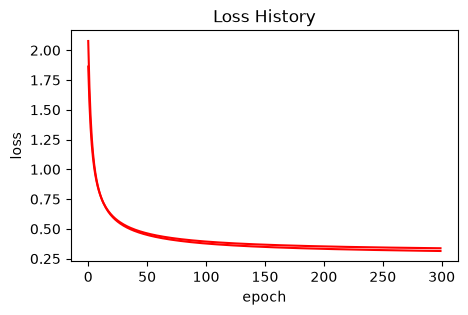

In [14]:
# Visually see the loss history
plt.figure(figsize=(5, 3))
plt.plot(hist.history['loss'], color='red')
plt.plot(hist.history['val_loss'], color='red')
plt.title("Loss History")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.show()

547/547 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
* Accuracy of the test data =0.8958


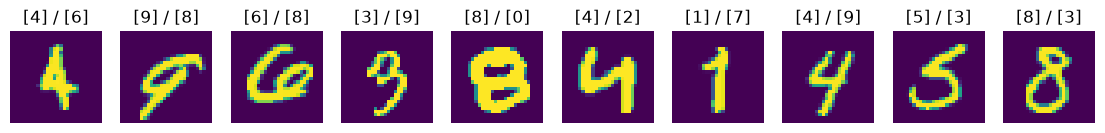

In [15]:
y_prob = model.predict(x_test)
y_pred = np.argmax(y_prob, axis=1).reshape(-1, 1)
acc = (y_test == y_pred).mean()
print('* Accuracy of the test data ={:.4f}'.format(acc))

# Let's check out some misclassified images.
n_sample = 10
miss_cls = np.where(y_test != y_pred)[0]
miss_sam = np.random.choice(miss_cls, n_sample)

fig, ax = plt.subplots(1, n_sample, figsize=(14, 4))
for i, miss in enumerate(miss_sam):
    x = x_test[miss]
    ax[i].imshow(x.reshape(28, 28))
    ax[i].axis('off')
    ax[i].set_title(str(y_test[miss]) + ' / ' + str(y_pred[miss]))